# Privacy Meter - RAMIA (Range Membership Inference Attack) Results Visualization

This notebook visualizes the results from the RAMIA privacy metric evaluation on CIFAR-10 with ResNet20.

## What is RAMIA?

RAMIA (Range Membership Inference Attack) tests if data **similar** to training samples can reveal privacy leaks. Unlike traditional MIA which checks exact membership, RAMIA checks the **neighborhood** around training points.

### Key Metrics:
- **Attack Accuracy**: How well the attack identifies training vs test samples
- **Privacy Leakage**: Accuracy - 0.5 (how much better than random guessing)
- **Precision**: Of samples predicted as training, how many actually were?
- **Recall**: Of actual training samples, how many were identified?
- **F1 Score**: Harmonic mean of precision and recall

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

## Load RAMIA Results

In [2]:
# Load the CSV results
df = pd.read_csv('../tests/data/measures/privacy_meter_ramia.csv')
print("RAMIA Metrics:")
print(df[['name', 'score']].to_string(index=False))

RAMIA Metrics:
                   name      score
  ramia_attack_accuracy   0.518000
        ramia_precision   0.518000
           ramia_recall   0.518000
         ramia_f1_score   0.518000
  ramia_privacy_leakage   0.018000
   ramia_true_positives 259.000000
   ramia_true_negatives 259.000000
  ramia_false_positives 241.000000
  ramia_false_negatives 241.000000
ramia_train_signal_mean   0.057258
 ramia_test_signal_mean   0.053526


## 1. Attack Performance Metrics

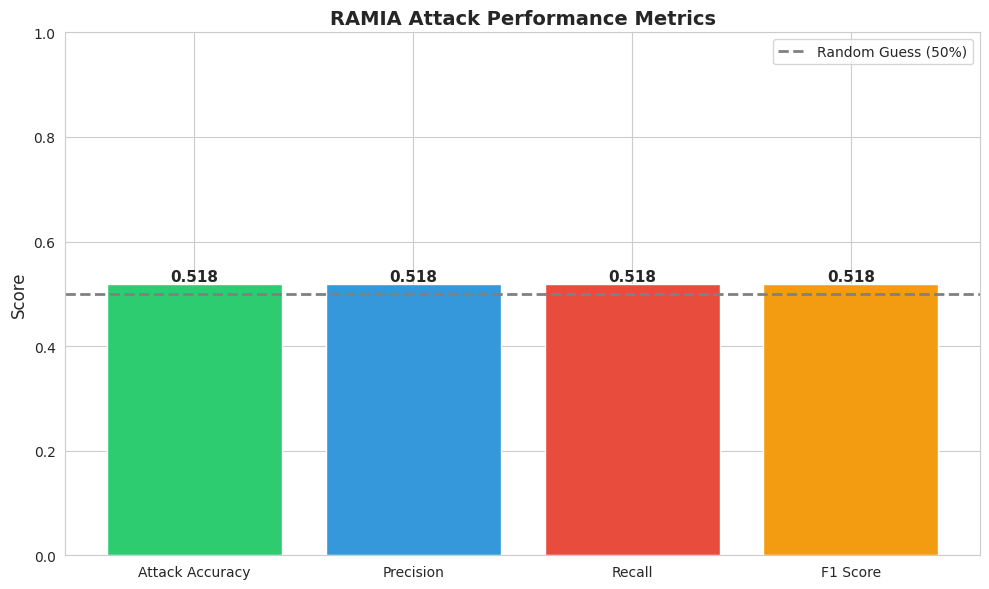

In [3]:
# Extract key performance metrics
perf_metrics = df[df['name'].isin([
    'ramia_attack_accuracy', 
    'ramia_precision', 
    'ramia_recall', 
    'ramia_f1_score'
])].copy()

perf_metrics['name'] = perf_metrics['name'].str.replace('ramia_', '').str.replace('_', ' ').str.title()

# Create bar plot
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(perf_metrics['name'], perf_metrics['score'], 
              color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])

# Add horizontal line at 0.5 (random guessing baseline)
ax.axhline(y=0.5, color='gray', linestyle='--', linewidth=2, label='Random Guess (50%)')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('RAMIA Attack Performance Metrics', fontsize=14, fontweight='bold')
ax.set_ylim(0, 1)
ax.legend()

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.3f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 2. Privacy Leakage Score

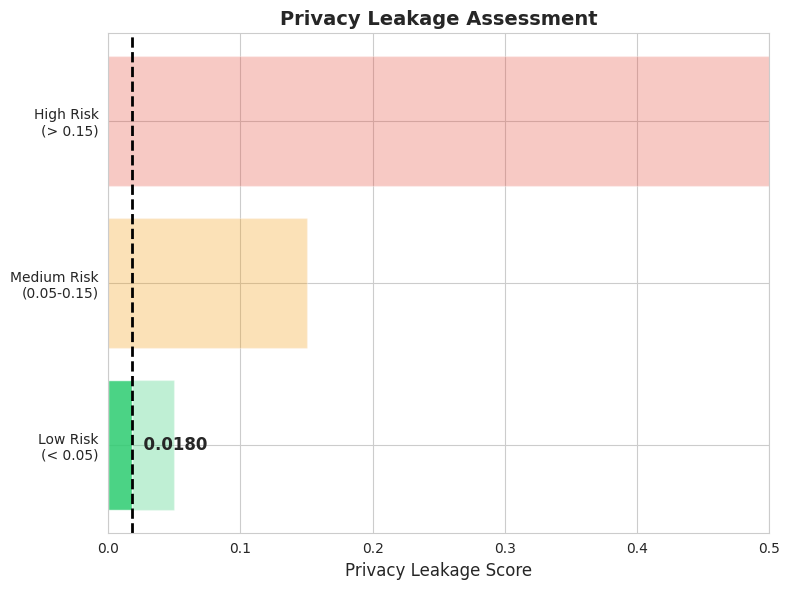


Privacy Leakage: 0.0180
Risk Level: Low Risk
(< 0.05)


In [4]:
privacy_leakage = df[df['name'] == 'ramia_privacy_leakage']['score'].values[0]

fig, ax = plt.subplots(figsize=(8, 6))

# Create gauge-style visualization
categories = ['Low Risk\n(< 0.05)', 'Medium Risk\n(0.05-0.15)', 'High Risk\n(> 0.15)']
colors = ['#2ecc71', '#f39c12', '#e74c3c']
ranges = [0.05, 0.15, 0.5]

bars = ax.barh(categories, ranges, color=colors, alpha=0.3)

# Mark the actual privacy leakage
if privacy_leakage < 0.05:
    category_idx = 0
elif privacy_leakage < 0.15:
    category_idx = 1
else:
    category_idx = 2

ax.barh(categories[category_idx], privacy_leakage, color=colors[category_idx], alpha=0.8)
ax.axvline(x=privacy_leakage, color='black', linestyle='--', linewidth=2)
ax.text(privacy_leakage, category_idx, f'  {privacy_leakage:.4f}', 
        va='center', fontsize=12, fontweight='bold')

ax.set_xlabel('Privacy Leakage Score', fontsize=12)
ax.set_title('Privacy Leakage Assessment', fontsize=14, fontweight='bold')
ax.set_xlim(0, 0.5)

plt.tight_layout()
plt.show()

print(f"\nPrivacy Leakage: {privacy_leakage:.4f}")
print(f"Risk Level: {categories[category_idx]}")

## 3. Confusion Matrix

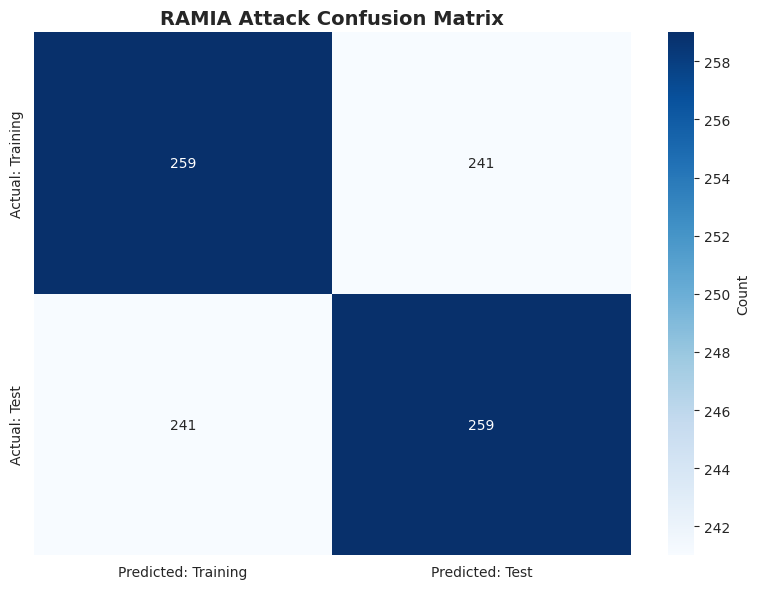


Total Samples: 1000
True Positives: 259 (25.9%)
True Negatives: 259 (25.9%)
False Positives: 241 (24.1%)
False Negatives: 241 (24.1%)


In [5]:
# Extract confusion matrix values
tp = df[df['name'] == 'ramia_true_positives']['score'].values[0]
tn = df[df['name'] == 'ramia_true_negatives']['score'].values[0]
fp = df[df['name'] == 'ramia_false_positives']['score'].values[0]
fn = df[df['name'] == 'ramia_false_negatives']['score'].values[0]

confusion_matrix = np.array([[tp, fp], [fn, tn]])

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='.0f', cmap='Blues', 
            xticklabels=['Predicted: Training', 'Predicted: Test'],
            yticklabels=['Actual: Training', 'Actual: Test'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_title('RAMIA Attack Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

total = tp + tn + fp + fn
print(f"\nTotal Samples: {total:.0f}")
print(f"True Positives: {tp:.0f} ({tp/total*100:.1f}%)")
print(f"True Negatives: {tn:.0f} ({tn/total*100:.1f}%)")
print(f"False Positives: {fp:.0f} ({fp/total*100:.1f}%)")
print(f"False Negatives: {fn:.0f} ({fn/total*100:.1f}%)")

## 4. RAMIA Signal Comparison

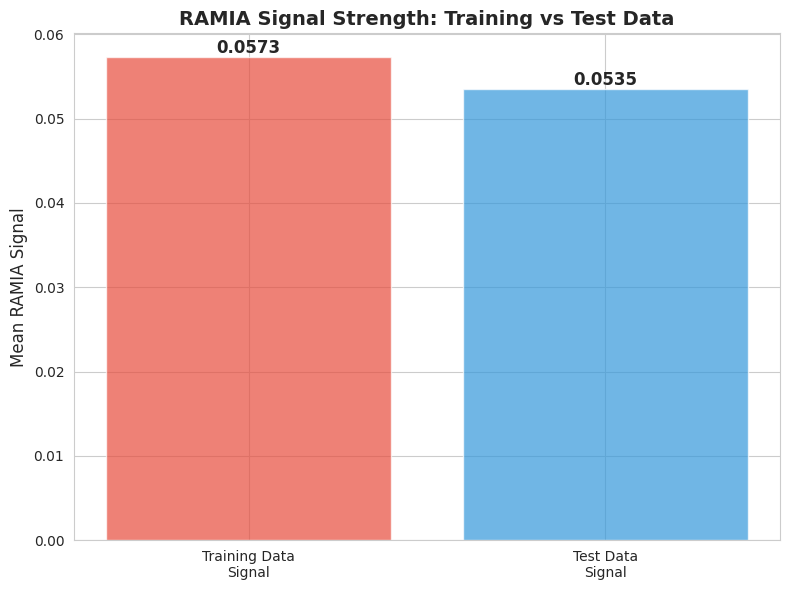


Training Signal: 0.0573
Test Signal: 0.0535
Difference: 0.0037

Interpretation: A larger difference indicates the model behaves differently
on training data vs test data in the neighborhood of samples.


In [5]:
# Extract signal means
train_signal = df[df['name'] == 'ramia_train_signal_mean']['score'].values[0]
test_signal = df[df['name'] == 'ramia_test_signal_mean']['score'].values[0]

fig, ax = plt.subplots(figsize=(8, 6))

signals = ['Training Data\nSignal', 'Test Data\nSignal']
values = [train_signal, test_signal]
colors = ['#e74c3c', '#3498db']

bars = ax.bar(signals, values, color=colors, alpha=0.7)

ax.set_ylabel('Mean RAMIA Signal', fontsize=12)
ax.set_title('RAMIA Signal Strength: Training vs Test Data', fontsize=14, fontweight='bold')

# Add value labels
for bar, value in zip(bars, values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{value:.4f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\nTraining Signal: {train_signal:.4f}")
print(f"Test Signal: {test_signal:.4f}")
print(f"Difference: {abs(train_signal - test_signal):.4f}")
print("\nInterpretation: A larger difference indicates the model behaves differently")
print("on training data vs test data in the neighborhood of samples.")

## 5. Summary Report

In [6]:
print("="*60)
print("RAMIA PRIVACY EVALUATION SUMMARY")
print("="*60)
print(f"\nModel: ResNet20")
print(f"Dataset: CIFAR-10")
print(f"Attack Type: Range Membership Inference Attack (RAMIA)")
print("\n" + "-"*60)
print("RESULTS:")
print("-"*60)

for _, row in df.iterrows():
    metric_name = row['name'].replace('ramia_', '').replace('_', ' ').title()
    score = row['score']
    if 'true_' in row['name'] or 'false_' in row['name']:
        print(f"{metric_name:.<50} {score:.0f}")
    else:
        print(f"{metric_name:.<50} {score:.4f}")

print("\n" + "="*60)
print("INTERPRETATION:")
print("="*60)

attack_acc = df[df['name'] == 'ramia_attack_accuracy']['score'].values[0]
privacy_leakage = df[df['name'] == 'ramia_privacy_leakage']['score'].values[0]

if attack_acc < 0.55:
    print("✓ LOW PRIVACY RISK: Attack accuracy is close to random guessing.")
    print("  The model shows minimal privacy leakage.")
elif attack_acc < 0.65:
    print("⚠ MEDIUM PRIVACY RISK: Attack has some success.")
    print("  The model may leak some training data information.")
else:
    print("✗ HIGH PRIVACY RISK: Attack is successful.")
    print("  The model significantly leaks training data information.")

print(f"\nPrivacy Leakage Score: {privacy_leakage:.4f}")
print("(Higher values indicate more privacy leakage)")
print("="*60)

RAMIA PRIVACY EVALUATION SUMMARY

Model: ResNet20
Dataset: CIFAR-10
Attack Type: Range Membership Inference Attack (RAMIA)

------------------------------------------------------------
RESULTS:
------------------------------------------------------------
Attack Accuracy................................... 0.5180
Precision......................................... 0.5180
Recall............................................ 0.5180
F1 Score.......................................... 0.5180
Privacy Leakage................................... 0.0180
True Positives.................................... 259
True Negatives.................................... 259
False Positives................................... 241
False Negatives................................... 241
Train Signal Mean................................. 0.0573
Test Signal Mean.................................. 0.0535

INTERPRETATION:
✓ LOW PRIVACY RISK: Attack accuracy is close to random guessing.
  The model shows minimal privacy lea